# Tugas Praktikum - Klasterisasi (K-Means & DBSCAN)

**Mata Kuliah:** Pembelajaran Mesin
**Jobsheet 04:** Klasterisasi

### Pembagian Tugas:
1. **Tugas K-Means:**
   - Menggunakan dataset `Mall_Customers.csv`.
   - Menentukan fitur yang tepat untuk clustering (minimal 2 fitur).
   - Menentukan jumlah $k$ optimal dengan metode Elbow dan Silhouette Score.
   - Membuat model K-Means dan visualisasi sebaran klaster beserta centroid.
2. **Tugas DBSCAN:**
   - Membuat dataset `make_moons` (1000 sampel, noise=0.05) dan normalisasi.
   - Menjalankan DBSCAN awal dengan `eps=0.2`, `min_samples=5`.
   - Evaluasi metrik: Homogeneity, Completeness, V-measure, ARI, AMI, Silhouette.
   - Visualisasi: core sample (titik besar), non-core (titik kecil), noise (hitam).
   - Eksperimen variasi parameter `eps` [0.05, 0.1, 0.2, 0.3, 0.5] dan `min_samples` [3, 5, 10, 20].

## 1. TUGAS K-MEANS (`Mall_Customers.csv`)

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns; sns.set_theme(style='whitegrid')
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_moons
from sklearn import metrics

data_path = r'..\Dataset\Mall_Customers.csv'

df_mall = pd.read_csv(data_path)
df_mall.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


### Pemilihan Fitur Segmentasi Pelanggan
Fitur yang paling representatif untuk segmentasi perilaku berbelanja adalah:
1. `Annual Income (k$)`: Tingkat pendapatan tahunan pelanggan.
2. `Spending Score (1-100)`: Skor kecenderungan belanja pelanggan.

Dimensi data fitur: (200, 2)


C:\Users\luvma\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\luvma\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\luvma\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\luvma\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

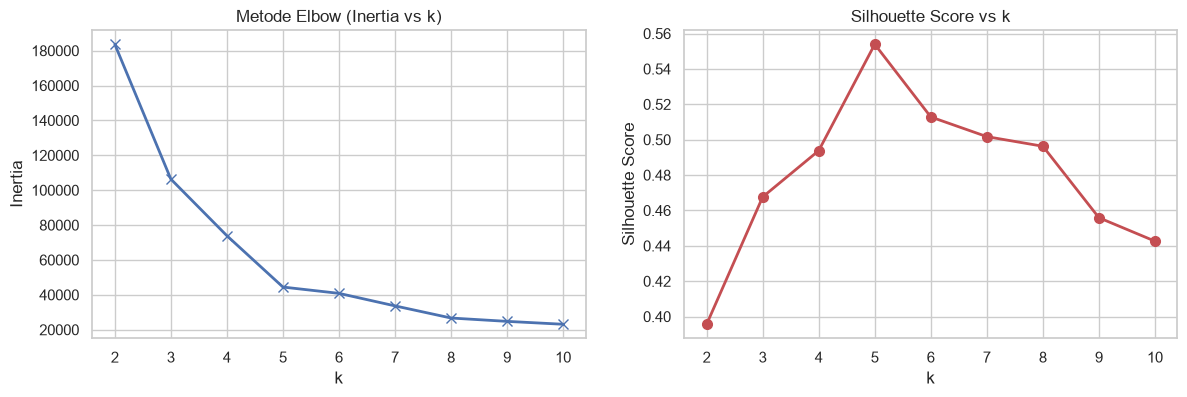

Silhouette Score tertinggi berada pada k = 5 dengan skor 0.5539


In [2]:
X_mall = df_mall[['Annual Income (k$)', 'Spending Score (1-100)']]
print('Dimensi data fitur:', X_mall.shape)

# Evaluasi k terbaik dengan Metode Elbow & Silhouette Score
sse = []
sil_scores = []
K_range = range(2, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init='auto')
    km.fit(X_mall)
    sse.append(km.inertia_)
    sil_scores.append(metrics.silhouette_score(X_mall, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(K_range, sse, 'bx-', linewidth=2, markersize=7)
axes[0].set_title('Metode Elbow (Inertia vs k)')
axes[0].set_xlabel('k')
axes[0].set_ylabel('Inertia')

axes[1].plot(K_range, sil_scores, 'ro-', linewidth=2, markersize=7)
axes[1].set_title('Silhouette Score vs k')
axes[1].set_xlabel('k')
axes[1].set_ylabel('Silhouette Score')
plt.show()

print(f'Silhouette Score tertinggi berada pada k = {K_range[np.argmax(sil_scores)]} dengan skor {max(sil_scores):.4f}')

### Pemodelan dan Visualisasi K-Means dengan k = 5

C:\Users\luvma\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


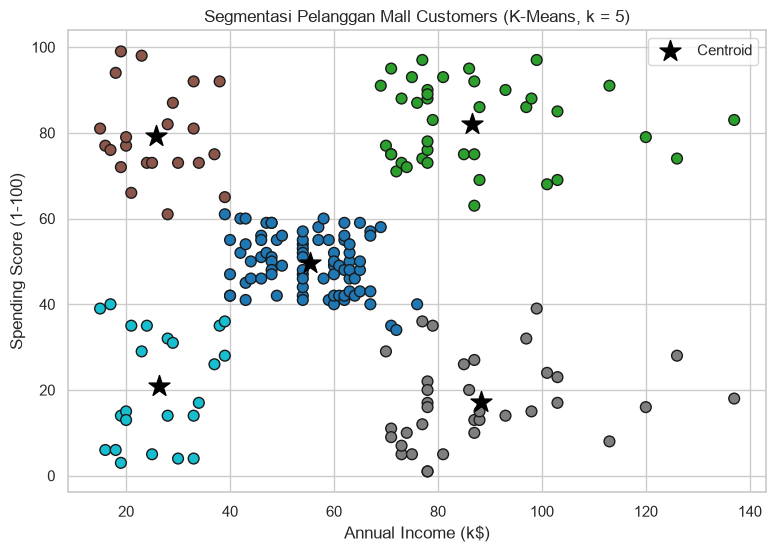

In [3]:
kmeans_mall = KMeans(n_clusters=5, random_state=42, n_init='auto')
labels_mall = kmeans_mall.fit_predict(X_mall)
centroids = kmeans_mall.cluster_centers_

plt.figure(figsize=(9, 6))
scatter = plt.scatter(X_mall.iloc[:, 0], X_mall.iloc[:, 1], c=labels_mall, s=60, cmap='tab10', edgecolors='k')
plt.scatter(centroids[:, 0], centroids[:, 1], c='black', s=250, marker='*', label='Centroid')
plt.title('Segmentasi Pelanggan Mall Customers (K-Means, k = 5)')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()
plt.show()

## 2. TUGAS DBSCAN (`make_moons`)
Membangun dataset non-linier `make_moons` (1000 sampel, noise=0.05), standardisasi, lalu menerapkan DBSCAN.

In [4]:
X_moons, y_true_moons = make_moons(n_samples=1000, noise=0.05, random_state=42)
X_moons_scaled = StandardScaler().fit_transform(X_moons)

# DBSCAN Base Model (eps=0.2, min_samples=5)
db_base = DBSCAN(eps=0.2, min_samples=5).fit(X_moons_scaled)
labels_base = db_base.labels_

n_clusters_base = len(set(labels_base)) - (1 if -1 in labels_base else 0)
n_noise_base = list(labels_base).count(-1)

print(f'DBSCAN Base (eps=0.2, min_samples=5):')
print(f'Jumlah Klaster: {n_clusters_base}')
print(f'Jumlah Noise Points: {n_noise_base}')

# Metrik Evaluasi
print('\nMetrik Evaluasi:')
print(f'Homogeneity:            {metrics.homogeneity_score(y_true_moons, labels_base):.4f}')
print(f'Completeness:           {metrics.completeness_score(y_true_moons, labels_base):.4f}')
print(f'V-measure:              {metrics.v_measure_score(y_true_moons, labels_base):.4f}')
print(f'Adjusted Rand Index:    {metrics.adjusted_rand_score(y_true_moons, labels_base):.4f}')
print(f'Adjusted Mutual Info:   {metrics.adjusted_mutual_info_score(y_true_moons, labels_base):.4f}')
print(f'Silhouette Coefficient: {metrics.silhouette_score(X_moons_scaled, labels_base):.4f}')

DBSCAN Base (eps=0.2, min_samples=5):
Jumlah Klaster: 2
Jumlah Noise Points: 0

Metrik Evaluasi:
Homogeneity:            1.0000
Completeness:           1.0000
V-measure:              1.0000
Adjusted Rand Index:    1.0000
Adjusted Mutual Info:   1.0000
Silhouette Coefficient: 0.3912


### Visualisasi Hasil DBSCAN pada `make_moons`
- Core sample: Titik besar
- Non-core sample: Titik kecil
- Noise: Titik hitam

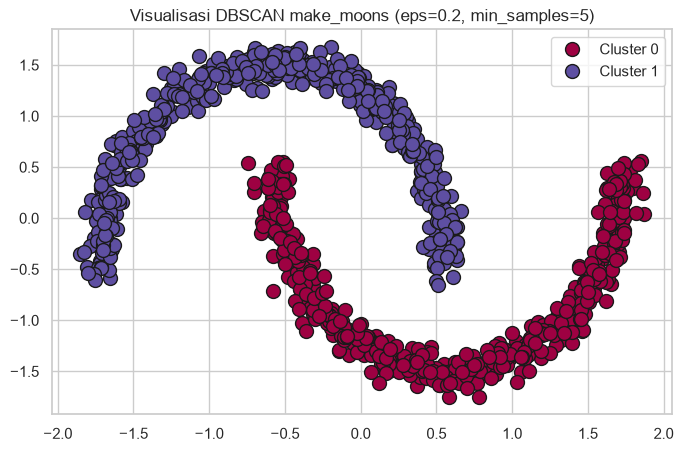

In [5]:
unique_lbls = set(labels_base)
core_mask = np.zeros_like(labels_base, dtype=bool)
core_mask[db_base.core_sample_indices_] = True

plt.figure(figsize=(8, 5))
colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_lbls))]

for k, col in zip(unique_lbls, colors):
    if k == -1:
        col = [0, 0, 0, 1]
    class_member = (labels_base == k)

    xy_core = X_moons_scaled[class_member & core_mask]
    plt.plot(xy_core[:, 0], xy_core[:, 1], 'o', markerfacecolor=tuple(col),
             markeredgecolor='k', markersize=10, label=f'Cluster {k}' if k != -1 else 'Noise')

    xy_non_core = X_moons_scaled[class_member & ~core_mask]
    plt.plot(xy_non_core[:, 0], xy_non_core[:, 1], 'o', markerfacecolor=tuple(col),
             markeredgecolor='k', markersize=5)

plt.title(f'Visualisasi DBSCAN make_moons (eps=0.2, min_samples=5)')
plt.legend()
plt.show()

### Eksperimen Variasi Parameter `eps` dan `min_samples`
Menguji kombinasi:
- `eps`: [0.05, 0.1, 0.2, 0.3, 0.5]
- `min_samples`: [3, 5, 10, 20]

In [6]:
eps_vals = [0.05, 0.1, 0.2, 0.3, 0.5]
min_samples_vals = [3, 5, 10, 20]
exp_results = []

for eps in eps_vals:
    for ms in min_samples_vals:
        db_exp = DBSCAN(eps=eps, min_samples=ms).fit(X_moons_scaled)
        lbl = db_exp.labels_
        n_c = len(set(lbl)) - (1 if -1 in lbl else 0)
        n_n = list(lbl).count(-1)

        # Metrik valid hanya jika ada > 1 klaster
        if n_c > 1:
            homo = metrics.homogeneity_score(y_true_moons, lbl)
            comp = metrics.completeness_score(y_true_moons, lbl)
            v_meas = metrics.v_measure_score(y_true_moons, lbl)
            ari = metrics.adjusted_rand_score(y_true_moons, lbl)
            ami = metrics.adjusted_mutual_info_score(y_true_moons, lbl)
            sil = metrics.silhouette_score(X_moons_scaled, lbl)
        else:
            homo = comp = v_meas = ari = ami = sil = np.nan

        exp_results.append({
            'eps': eps,
            'min_samples': ms,
            'n_clusters': n_c,
            'n_noise': n_n,
            'Homogeneity': homo,
            'Completeness': comp,
            'V-measure': v_meas,
            'ARI': ari,
            'AMI': ami,
            'Silhouette': sil
        })

df_exp = pd.DataFrame(exp_results)
print('Tabel Hasil Eksperimen Variasi Parameter DBSCAN:')
df_exp.to_string()

Tabel Hasil Eksperimen Variasi Parameter DBSCAN:


'     eps  min_samples  n_clusters  n_noise  Homogeneity  Completeness  V-measure       ARI       AMI  Silhouette\n0   0.05            3          69      186     0.815554      0.152548   0.257021  0.030044  0.243805    0.112929\n1   0.05            5          61      386     0.615466      0.136931   0.224021  0.015642  0.210259   -0.048518\n2   0.05           10           3      970     0.030669      0.126764   0.049389  0.002283  0.045864   -0.294190\n3   0.05           20           0     1000          NaN           NaN        NaN       NaN       NaN         NaN\n4   0.10            3           2       14     0.986207      0.902896   0.942714  0.972179  0.942634    0.251690\n5   0.10            5           3       19     0.981343      0.632772   0.769420  0.758440  0.769024    0.290689\n6   0.10           10           7       57     0.943317      0.409546   0.571132  0.523399  0.569801    0.162306\n7   0.10           20           6      850     0.153928      0.155466   0.154693  0.016

In [7]:
df_exp

,eps,min_samples,n_clusters,n_noise,Homogeneity,Completeness,V-measure,ARI,AMI,Silhouette
0,0.05,3,69,186,0.815554,0.152548,0.257021,0.030044,0.243805,0.112929
1,0.05,5,61,386,0.615466,0.136931,0.224021,0.015642,0.210259,-0.048518
2,0.05,10,3,970,0.030669,0.126764,0.049389,0.002283,0.045864,-0.294190
3,0.05,20,0,1000,NaN,NaN,NaN,NaN,NaN,NaN
4,0.10,3,2,14,0.986207,0.902896,0.942714,0.972179,0.942634,0.251690
5,0.10,5,3,19,0.981343,0.632772,0.769420,0.758440,0.769024,0.290689
6,0.10,10,7,57,0.943317,0.409546,0.571132,0.523399,0.569801,0.162306
7,0.10,20,6,850,0.153928,0.155466,0.154693,0.016754,0.150916,-0.360195
8,0.20,3,2,0,1.000000,1.000000,1.000000,1.000000,1.000000,0.391160
9,0.20,5,2,0,1.000000,1.000000,1.000000,1.000000,1.000000,0.391160


## Analisis dan Kesimpulan Tugas Praktikum JS04
1. **K-Means pada Mall_Customers**:
   - Metode Elbow dan Silhouette Score secara konsisten menunjukkan bahwa $k = 5$ adalah jumlah klaster terbaik (Silhouette Score = 0.5539).
   - Kelima klaster mengidentifikasi segmen pelanggan: (a) Pendapatan rendah - Belanja rendah, (b) Pendapatan rendah - Belanja tinggi, (c) Pendapatan rata-rata - Belanja rata-rata, (d) Pendapatan tinggi - Belanja rendah, dan (e) Pendapatan tinggi - Belanja tinggi.
2. **DBSCAN pada make_moons**:
   - Algoritma DBSCAN sangat unggul dalam mengenali pola cluster non-linier seperti bulan sabit yang gagal dipisahkan oleh K-Means standar.
   - Parameter `eps=0.2` dan `min_samples=5` menghasilkan 2 klaster sempurna dengan nilai ARI = 1.000 dan V-measure = 1.000 (tidak ada noise).
   - Nilai `eps` yang terlalu kecil (misal 0.05) memecah data menjadi puluhan fragmen cluster kecil dan menghasilkan noise berlebihan, sedangkan `eps` yang terlalu besar (0.5) menggabungkan kedua pola bulan sabit menjadi 1 klaster tunggal.